# შუალედური გამოცდა

In [11]:
import pandas as pd
import matplotlib.pyplot as plt

import cartopy.crs as ccrs
import cartopy.feature as cfeature

## მაღაზიების მდებარეობის ანალიზი  (Analysis of Store Locations)

`../../datasets/retailer_data/` - აქ არის მონაცემები, რომლებიც ამ დავალებებისთვის დაგჭირდებათ (`Data_1`, `Data_2`, `Sales_1`).

თქვენ გაქვთ `Data_1` მონაცემთა ნაკრები, სადაც თითოეული ჩანაწერი შეესაბამება მაღაზიას სხვადასხვა სასურსათო საცალო ვაჭრობიდან.

### 1. პირველადი შთაბეჭდილება (First Impression)
- წაიკითხეთ მონაცემები
- რა შეგიძლიათ თქვათ მონაცემთა ხარისხზე?  
- რომელი ნაბიჯების გადადგმაა შესაძლებელი მონაცემთა ხარისხის გასაუმჯობესებლად? 

In [ ]:
# your code here

### 2. სიღრმისეული ანალიზი და საცალო ვაჭრობის იდენტიფიკაცია  (Deeper Analysis and Retailer Identification)
- მონაცემების ღრმა ანალიზის შემდეგ, რა შეგიძლიათ თქვათ სხვადასხვა საცალო ბრენდებზე?  
- თქვენ გეძლევათ დამატებითი მონაცემთა ნაკრები `Data_2`, რომელიც არ შეიცავს საცალო ბრენდის ინფორმაციას, მაგრამ იგივე ტიპის მონაცემებს წარმოადგენს.  
  - გააკეთეთ პროგნოზი საცალო ბრენდი `Data_2`-ისთვის, გამოიყენეთ `Data_1`-ის მონაცემები (`Retailer` სვეტის პროგნოზირება)
  - ახსნეთ თქვენი მეთოდოლოგია.  
  - რა შეიძლება გაუმჯობესდეს ამ პროცესში?  

In [ ]:
# your code here

### 3. რუკაზე მაღაზიების ადგილმდებარეობების ასახვა
- ქვემოთ მოცემულია მაგალითი, როგორ შეგვიძლია ლონგიტუდისა და ლატიდუდის ინფორმაციის რუკაზე ასახვა. 
- გაანალიზეთ მოცემული მაგალითი.

#### Plotting geographical data: SimpleMaps World Cities dataset

In [12]:
# მონაცემების წაკითხვა
file_path = "../../datasets/simple_maps_world_cities/worldcities.csv"
df = pd.read_csv(file_path)

# გავფილტროთ მონაცემები
european_countries = ["Germany", "France", "Italy", "Spain", "United Kingdom", "Netherlands", "Sweden", "Poland", "Greece"]
df_europe = df[df["country"].isin(european_countries)].reset_index(drop=True)[["city", "country", "lat", "lng"]]
df_europe.head()

,city,country,lat,lng
0,London,United Kingdom,51.5072,-0.1275
1,Paris,France,48.8567,2.3522
2,Madrid,Spain,40.4169,-3.7033
3,Berlin,Germany,52.5200,13.4050
4,Barcelona,Spain,41.3828,2.1769


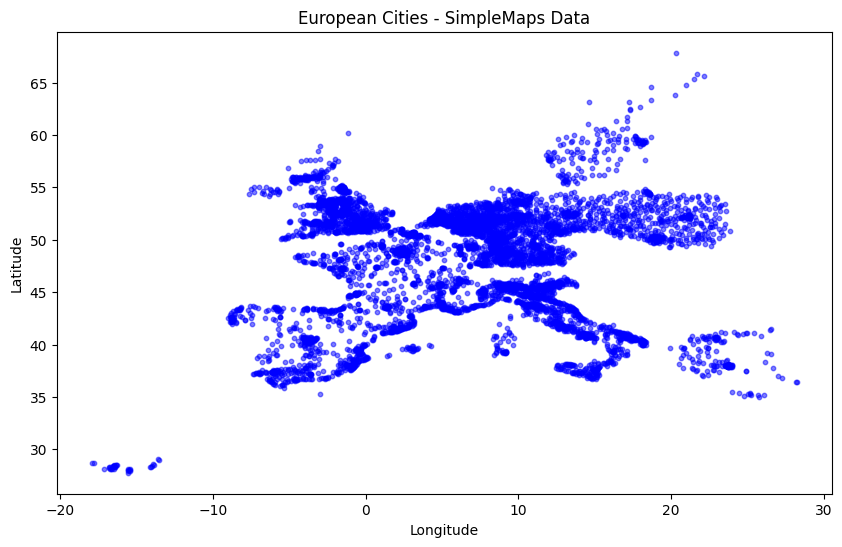

In [13]:
# Longitude vs. Latitude
plt.figure(figsize=(10, 6))
plt.scatter(df_europe["lng"], df_europe["lat"], alpha=0.5, s=10, color="blue")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("European Cities - SimpleMaps Data")
plt.show()

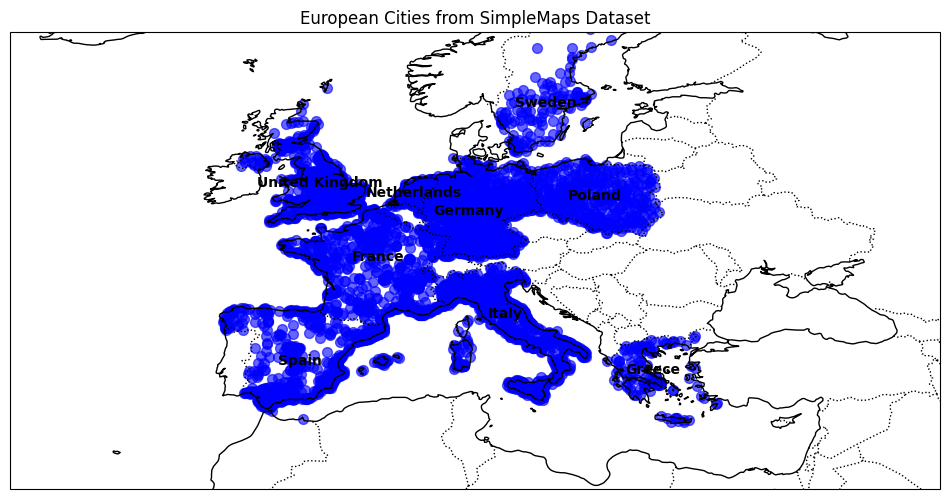

In [17]:
# შევქმნათ Cartopy map
fig, ax = plt.subplots(figsize=(12, 8), subplot_kw={'projection': ccrs.PlateCarree()})
ax.set_extent([-25, 45, 30, 60])  # boundaries

# ქვეყნების საზღვრები დავამატოთ
ax.add_feature(cfeature.BORDERS, linestyle=':')
ax.add_feature(cfeature.COASTLINE)

# ქალაქები მოვნიშნოთ რუკაზე
ax.scatter(df_europe["lng"], df_europe["lat"], color='blue', marker='o', s=50, alpha=0.6, transform=ccrs.PlateCarree())

# ქვეყნების სახელები მოვნიშნოთ
country_labels = df_europe.groupby("country").agg({"lat": "mean", "lng": "mean"}).reset_index()
for _, row in country_labels.iterrows():
    ax.text(row["lng"], row["lat"], row["country"], fontsize=10, ha='center', fontweight='bold', transform=ccrs.PlateCarree())

plt.title("European Cities from SimpleMaps Dataset")
plt.show()

ამ მაგალითის დახმარებით შექმენით გრაფიკი, დაიტანეთ რუკაზე მაღაზიების ადგილმდებარეობა. 

In [15]:
# ქვეყნების ლოკაცია 
country_names = {
    'France': (46.5, 2.5),
    'Germany': (51.0, 10.5),
    'Poland': (52.0, 19.0),
    'Belgium': (50.8, 4.5),
    'Netherlands': (52.5, 5.0),
    'Spain': (40.4168, -3.7038),
    'Portugal': (39.3999, -8.2245),
    'Denmark': (56.2639, 9.5018),
    'Luxembourg': (49.6118, 6.1319),
}

# your code here

### 4. გაყიდვების პროგნოზი  (Sales Prediction)
თქვენ გეძლევათ დამატებითი მონაცემები `Sales_1`, რომელიც შეესაბამება `Data_1`-ს და შეიცავს გაყიდვების მთლიანი შემოსავალს (1000€ წელიწადში) გარკვეული მაღაზიებისთვის საცალო ვაჭრობის A ბრენდიდან გერმანიაში.  
- შექმენით მარტივი გაყიდვების პროგნოზის მოდელი, რომელიც შეძლებს ახალი მაღაზიის გაყიდვების შეფასებას. გამოიყენეთ მოდელი საცალო ვაჭრობის A ბრენდის მაღაზიებზე გერმანიაში, სადაც გაყიდვების მონაცემები აკლია (`Sales` სვეტის პროგნოზირება).

    - რომელი მახასიათებლები (features) მიგაჩნიათ ყველაზე მნიშვნელოვანად?  
    - არის სხვა მახასიათებლები, რომლებიც შეგვიძლია დავამატოთ?

In [ ]:
# your code here